## Step 2: Database building

Turning 6 raw CSV files into a populated queryable SQLite database (database/ebergy.db), using the satr schema defined in sql/create_tables.sql

Steps:

1. Connecting to SQLite and creating the schema
2. Building the 2 lookup dimnesions (time_periods, calendar_info)
3. Loading and harmonising the 3 demand CSVs (date format differs)
4. Loading the weather data (with timezone check)
5. Verifying everything with SQL queries

### 1. Setup & paths

In [1]:

import sqlite3
from pathlib import Path
from datetime import datetime, timedelta


import pandas as pd   
import numpy as np     


pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

#Project roots
CWD=Path.cwd()
PROJECT_ROOT=CWD.parent if CWD.name=="notebooks" else CWD

RAW_DIR=PROJECT_ROOT / "data" / "raw"
DB_DIR=PROJECT_ROOT / "database"
SQL_DIR=PROJECT_ROOT / "sql"
DB_PATH=DB_DIR / "energy.db"

#Creating folders
DB_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")
print(f"Database: {DB_PATH}")
print(f"SQL: {SQL_DIR}")

print("Files found in data/raw:")
for f in sorted(RAW_DIR.glob("*.csv")):
    print(f" {f.name:<35} {f.stat().st_size / 1_000_000:>6.2f} MB")

Project root: c:\Users\marco\Documents\PROJECTS\New folder
Raw data: c:\Users\marco\Documents\PROJECTS\New folder\data\raw
Database: c:\Users\marco\Documents\PROJECTS\New folder\database\energy.db
SQL: c:\Users\marco\Documents\PROJECTS\New folder\sql
Files found in data/raw:
 bank_holidays.csv                     0.00 MB
 demanddata_2023.csv                   1.73 MB
 demanddata_2024.csv                   1.81 MB
 demanddata_2025.csv                   1.85 MB
 school_holidays.csv                   0.00 MB
 weather_london_2023_2025.csv          1.11 MB


### 2. Connecting to SQLite & creating the schema

In [ ]:
#Connecting
conn=sqlite3.connect(DB_PATH)
cur=conn.cursor()

#Turning on foreign key enforcement
cur.execute("PRAGMA foreign_keys=ON;")

#Reading & running the schea file
schema_sql=(SQL_DIR / "create_tables.sql").read_text(encoding="utf-8-sig")
cur.executescript(schema_sql)
conn.commit()

#Confirming
tables=pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",conn
)
print("Tables created:")
print(tables.to_string(index=False))


Tables created:
              name
         anomalies
     calendar_info
   demand_readings
model_features_tbl
 model_predictions
      time_periods
    weather_hourly


### 3. Building time-periods (50 rows)

Period 'p' covers the half hour starting at (p-1) *30 minutes after midnight.

Periods 49 and 40 only exist on the Oct. clock-change day (clocks go back --> +1 extra hour)

In [ ]:
def build_time_periods() -> pd.DataFrame:
    rows=[]

    for p in range(1,51):
        if p<=48:
            #Normal case: mins since midnight = (p-1) *30
            total_minutes=(p-1)*30
            hour=total_minutes //60
            minute=total_minutes % 60
            clock_only=0
        else:
            #Periods 49-50 in October, they map to the final hour of the day - 23:00-00:00
            hour=23
            minute=0 if p==49 else 30
            clock_only=1

        #End of the slot for the label. Wrapping to 00:00 at the end of the day
        end_minutes=(hour*60+minute+30) % (24*60)
        end_h, end_m=end_minutes // 60, end_minutes % 60

        #COarse buckets for dashboard slicing
        if hour < 6:
            pod="Night"
        elif hour<12:
            pod="Morning"
        elif hour<18:
            pod="Afternoon"
        else:
            pod="Evening"


        # Peak definition
        is_peak=1 if 16<=hour<=19 else 0

        rows.append({
            "settlement_period": p,
            "hour": hour,
            "minute": minute,
            "time_label": f"{hour:02d}:{minute:02d}-{end_h:02d}:{end_m:02d}",
            "hour_decimal": hour+minute/60,
            "period_of_day": pod,
            "is_peak": is_peak,
            "is_clock_change_only": clock_only,
        })

    return pd.DataFrame(rows)

time_periods=build_time_periods()

#Writing to database
time_periods.to_sql("time_periods", conn, if_exists="append", index=False)
conn.commit()

print(f"Inserted {len(time_periods)} rows into time_periods")
print("Spot check the evening peak:")
print(time_periods[time_periods["is_peak"]==1].head(8).to_string(index=False))

        

Inserted 50 rows into time_periods
Spot check the evening peak:
 settlement_period  hour  minute  time_label  hour_decimal period_of_day  is_peak  is_clock_change_only
                33    16       0 16:00-16:30          16.0     Afternoon        1                     0
                34    16      30 16:30-17:00          16.5     Afternoon        1                     0
                35    17       0 17:00-17:30          17.0     Afternoon        1                     0
                36    17      30 17:30-18:00          17.5     Afternoon        1                     0
                37    18       0 18:00-18:30          18.0       Evening        1                     0
                38    18      30 18:30-19:00          18.5       Evening        1                     0
                39    19       0 19:00-19:30          19.0       Evening        1                     0
                40    19      30 19:30-20:00          19.5       Evening        1                     0


### 4.  Harmonising the date formats

As 5 files contains 4 different date formats:
* demanddata_2023:                  01-Jan-23
* demanddata_2024 and _2025:        01-JAN-2024  
* weather_london_2023_2025:         2023-01-01 
* bank_holidays, school_holidays:   13/02/2023 

pd.to_datetime without a format will infer (01-02-2024 could be inserted as 1 February in one file and 2 January in another)

In [4]:
KNOWN_DATE_FORMATS={
    # 2025-01-01
    "%Y-%m-%d",
    # 01-JAN-2024     
    "%d-%b-%Y",
    # 01-Jan-23     
    "%d-%b-%y", 
    # 13/02/2023   
    "%d/%m/%Y",     
}

#Function to parse a series of date strings usint the list of formats
def parse_dates_strict(series: pd.Series, filename:str="") -> pd.Series:

    s=series.astype(str).str.strip()

    for fmt in KNOWN_DATE_FORMATS:
        parsed=pd.to_datetime(s, format=fmt, errors="coerce")
        if parsed.notna().all():
            print(f" {filename}: matched format '{fmt}'")
            return parsed

    # Checking for errors
    sample=s.head(3).tolist()
    raise ValueError(
        f"No known date format fits {filename}. "
        f"Sample values: {sample}. --> format needs to be added to format list"
    )

print("Raw date formats as found:")
for year in (2023, 2024, 2025):
    path=RAW_DIR / f"demanddata_{year}.csv"
    first=pd.read_csv(path, nrows=1)
    print(f" {year}: {first['SETTLEMENT_DATE'].iloc[0]!r}")





Raw date formats as found:
 2023: '01-Jan-23'
 2024: '01-JAN-2024'
 2025: '01-JAN-2025'


### 5. Loading the 3 demand files

Selecting a defined subset of columns and renaming them to schema names:
 - if NESO renames/drops columns in a future download, a warning will be displayed

_FLOW columns are deliberately excluded.

In [5]:
# Source column --> database column
COLUMN_MAP={
    "SETTLEMENT_DATE":          "settlement_date",
    "SETTLEMENT_PERIOD":        "settlement_period",
    #target variable
    "TSD":                      "tsd_mw",
    "ND":                       "nd_mw",
    "ENGLAND_WALES_DEMAND":     "england_wales_demand_mw",
    "EMBEDDED_WIND_GENERATION": "embedded_wind_mw",
    "EMBEDDED_SOLAR_GENERATION": "embedded_solar_mw",
    "PUMP_STORAGE_PUMPING":      "pump_storage_mw",   
}

def load_demand_year(year:int) -> pd.DataFrame:

    #loading 1 year of demand data and returning it in a schema-ready form
    path=RAW_DIR / f"demanddata_{year}.csv"
    df=pd.read_csv(path)

    #Stripping whitespace from headers
    df.columns=df.columns.str.strip()

    # Checking for missing columns
    missing=[c for c in COLUMN_MAP if c not in df.columns]
    if missing:
        print(f"{year}: expected columns not found --> {missing}")

    # Keeping and renaming the present columns
    present=[c for c in COLUMN_MAP if c in df.columns]
    df=df[present].rename(columns=COLUMN_MAP)

    #Synchronising the date, storing an ISO text for SQLite
    df["settlement_date"]=parse_dates_strict(
        df["settlement_date"], filename=f"demanddata_{year}.csv"
    ).dt.strftime("%Y-%m-%d")

    df["settlement_period"]=df["settlement_period"].astype(int)

    print(f" {year}: {len(df):,} rows loaded")

    return df

print("Loading demand data:")
demand=pd.concat(
    [load_demand_year(y) for y in (2023,2024,2025)],
    ignore_index=True,
)

print(f"\nCombined: {len(demand):,} rows, {demand['settlement_date'].nunique():,} distinct dates")
print(f"Date range: {demand['settlement_date'].min()} to {demand['settlement_date'].max()}")
demand.head()

Loading demand data:
 demanddata_2023.csv: matched format '%d-%b-%y'
 2023: 17,520 rows loaded
 demanddata_2024.csv: matched format '%d-%b-%Y'
 2024: 17,568 rows loaded
 demanddata_2025.csv: matched format '%d-%b-%Y'
 2025: 17,520 rows loaded

Combined: 52,608 rows, 1,096 distinct dates
Date range: 2023-01-01 to 2025-12-31


,settlement_date,settlement_period,tsd_mw,nd_mw,england_wales_demand_mw,embedded_wind_mw,embedded_solar_mw,pump_storage_mw
0,2023-01-01,1,24680,21043,18995,2815,0,1161
1,2023-01-01,2,25289,21756,19730,2793,0,1056
2,2023-01-01,3,25269,21348,19327,2773,0,1212
3,2023-01-01,4,24574,20586,18589,2753,0,1237
4,2023-01-01,5,24135,19781,17806,2712,0,1233


### 6. Diagnostic

Checking for:
* Duplicate keys
* Settlement period range (if 46/50 clock change days periods are present)
* missing target values
* TSD range

In [6]:
print("DIAGNOSTIC 1: duplicate (date, period) keys")

dupes=demand.duplicated(subset=["settlement_date", "settlement_period"], keep=False)
print(f"Duplicate ros: {dupes.sum():,}")
if dupes.any():
    print(demand[dupes].sort_values(["settlement_date", "settlement_period"]).head(10))

print("\nDIAGNOSTIC 2: settlement periods per day (clock-change check)")
periods_per_day=demand.groupby("settlement_date").size()
print("Distribution of period counts per day:")
print(periods_per_day.value_counts().sort_index().to_string())

odd_days=periods_per_day[periods_per_day !=48]
if len(odd_days)>0:
    print(f"\n{len(odd_days)} days do not have 48 periods, these are the clock-changes:")
    print(odd_days.to_string())
else:
    print("\n All days have exactly 48 periods")

print("\nDIAGNOSTIC 3: missing values")
print(demand.isna().sum().to_string())

print("\nDIAGNOSTIC 4: TSD range")
print(demand["tsd_mw"].describe().to_string())
out_of_range=demand[(demand["tsd_mw"] < 10_000) | (demand["tsd_mw"] > 60_000)]

print(f"\nRows outside 10,000-60,000 MW: {len(out_of_range):,}")
if len(out_of_range)>0:
    print(out_of_range.head())


DIAGNOSTIC 1: duplicate (date, period) keys
Duplicate ros: 0

DIAGNOSTIC 2: settlement periods per day (clock-change check)
Distribution of period counts per day:
46       3
48    1090
50       3

6 days do not have 48 periods, these are the clock-changes:
settlement_date
2023-03-26    46
2023-10-29    50
2024-03-31    46
2024-10-27    50
2025-03-30    46
2025-10-26    50

DIAGNOSTIC 3: missing values
settlement_date            0
settlement_period          0
tsd_mw                     0
nd_mw                      0
england_wales_demand_mw    0
embedded_wind_mw           0
embedded_solar_mw          0
pump_storage_mw            0

DIAGNOSTIC 4: TSD range
count    52608.000000
mean     28235.455026
std       5863.946614
min      15297.000000
25%      23776.000000
50%      27118.000000
75%      31806.000000
max      47760.000000

Rows outside 10,000-60,000 MW: 0


### 7. Building calendar_info

1 row per date across the full period

In [7]:
# Bank holidays
###################################################


bank_df = pd.read_csv(RAW_DIR / "bank_holidays.csv")
bank_df.columns = bank_df.columns.str.strip().str.lower()
print(f"bank_holidays.csv columns: {list(bank_df.columns)}")

bank_date_col  = "date"
bank_title_col = "title"

#Parsing to ISO. keys must match calendar_date, which is 'YYYY-MM-DD'
bank_df["_date"] = parse_dates_strict(
    bank_df[bank_date_col], "bank_holidays.csv"
).dt.strftime("%Y-%m-%d")

bank_lookup = dict(zip(bank_df["_date"], bank_df[bank_title_col]))

# Verifying
print(f"  -> {len(bank_lookup)} bank holidays loaded")
print(f"  -> sample keys: {list(bank_lookup)[:3]}")
assert all("-" in k and len(k) == 10 for k in bank_lookup), \
    "bank_lookup keys are not ISO format."

#School holidays
###################################################
school_df=pd.read_csv(RAW_DIR / "school_holidays.csv")
school_df.columns=school_df.columns.str.strip().str.lower()
print(f"\nschool_holidays.csv columns: {list(school_df.columns)}")

school_dates= set()

starts=parse_dates_strict(school_df["start_date"], "school holiday start")
ends=parse_dates_strict(school_df["end_date"], "school holiday end")

for s,e in zip(starts, ends):
    school_dates.update(pd.date_range(s,e, freq="D").strftime("%Y-%m-%d"))


print(f" --> {len(school_dates):,} individual school holiday days")



bank_holidays.csv columns: ['title', 'date', 'notes', 'bunting']
 bank_holidays.csv: matched format '%d/%m/%Y'
  -> 83 bank holidays loaded
  -> sample keys: ['2019-01-01', '2019-04-19', '2019-04-22']

school_holidays.csv columns: ['start_date', 'end_date', 'holiday_name']
 school holiday start: matched format '%d/%m/%Y'
 school holiday end: matched format '%d/%m/%Y'
 --> 266 individual school holiday days


Assembling the calendar. Computing clock-change dates --> last Sunday in March and last Sunday in October, per year

In [8]:
#Function to return the last Sunday of given months as 'YYYY-MM-DD'
def last_sunday(year:int, month:int) -> str:
    #Satrting at the first day of the next month, stepping back to previous Sunday
    nxt=datetime(year + (month==12), (month%12) +1, 1)
    d=nxt-timedelta(days=1)
    #6 is Sunday in weekday()
    while d.weekday() !=6:
        d -=timedelta(days=1)
    return d.strftime("%Y-%m-%d")

SEASON_MAP={12: "Winter", 1: "Winter", 2:"Winter",
            3: "Spring",  4: "Spring",  5: "Spring",
            6: "Summer",  7:"Summer",  8: "Summer",
            9: "Autumn", 10: "Autumn", 11: "Autumn"}


#building the date spine from the demand data
start=demand["settlement_date"].min()
end=demand["settlement_date"].max()
all_dates = pd.date_range(start, pd.Timestamp(end) + pd.Timedelta(days=7), freq="D")

years=sorted({d.year for d in all_dates})
clock_change_dates=set()
for y in years:
    clock_change_dates.add(last_sunday(y,3))
    clock_change_dates.add(last_sunday(y,10))

calendar=pd.DataFrame({"calendar_date": all_dates.strftime("%Y-%m-%d")})
calendar["year"]=all_dates.year
calendar["month"]=all_dates.month
calendar["month_name"]=all_dates.strftime("%B")
calendar["day_of_month"]=all_dates.day
calendar["day_of_year"]=all_dates.dayofyear
calendar["day_of_week"]=all_dates.weekday
calendar["day_name"]=all_dates.strftime("%A")
calendar["season"]=calendar["month"].map(SEASON_MAP)

calendar["is_weekend"]=(calendar["day_of_week"]>=5).astype(int)
calendar["is_bank_holiday"]=calendar["calendar_date"].isin(bank_lookup).astype(int)
calendar["bank_holiday_name"]=calendar["calendar_date"].map(bank_lookup)
calendar["is_school_holiday"]=calendar["calendar_date"].isin(school_dates).astype(int)


#Working day, a weekday that is not a bank holiday
calendar["is_working_day"]=(
    (calendar["is_weekend"]==0) & (calendar["is_bank_holiday"]==0)

).astype(int)

calendar["is_clock_change_day"]= calendar["calendar_date"].isin(clock_change_dates).astype(int)

calendar.to_sql("calendar_info", conn, if_exists="append", index=False)
conn.commit()

print(f"Inserted {len(calendar):,} rows into calendar_info")
print(f"Bank holidays flagged:  {calendar['is_bank_holiday'].sum()}")
print(f"School holiday days:    {calendar['is_school_holiday'].sum()}")
print(f"Working days:           {calendar['is_working_day'].sum():,}")
print(f"Clock change days:      {sorted(clock_change_dates)}")
calendar.head()



Inserted 1,103 rows into calendar_info
Bank holidays flagged:  26
School holiday days:    266
Working days:           762
Clock change days:      ['2023-03-26', '2023-10-29', '2024-03-31', '2024-10-27', '2025-03-30', '2025-10-26', '2026-03-29', '2026-10-25']


,calendar_date,year,month,month_name,day_of_month,day_of_year,day_of_week,day_name,season,is_weekend,is_bank_holiday,bank_holiday_name,is_school_holiday,is_working_day,is_clock_change_day
0,2023-01-01,2023,1,January,1,1,6,Sunday,Winter,1,0,NaN,0,0,0
1,2023-01-02,2023,1,January,2,2,0,Monday,Winter,0,1,New Year’s Day,0,0,0
2,2023-01-03,2023,1,January,3,3,1,Tuesday,Winter,0,0,NaN,0,1,0
3,2023-01-04,2023,1,January,4,4,2,Wednesday,Winter,0,0,NaN,0,1,0
4,2023-01-05,2023,1,January,5,5,3,Thursday,Winter,0,0,NaN,0,1,0


### 8. Inserting the demand facts



In [9]:
demand_cols=[
    "settlement_date", "settlement_period", "tsd_mw","nd_mw",
    "england_wales_demand_mw", "embedded_wind_mw","embedded_solar_mw",
    "pump_storage_mw",
]

demand_to_insert=demand[[c for c in demand_cols if c in demand.columns]]

demand_to_insert.to_sql("demand_readings", conn, if_exists="append",
                        index=False, chunksize=5000)
conn.commit()

count=pd.read_sql_query("SELECT COUNT(*) AS n FROM demand_readings;",conn)["n"].iloc[0]

print(f"demand_reading holds {count:,} rows")

demand_reading holds 52,608 rows


### 9.Loading weather data & timezone check

API was set to timezone: "Europe/London", double-checking if weather data uses UTC or local time. If it's local time,
summer days' lowest temperature will be found at 05:00, if it uses UTC summer days' lowest temeprature will
be at 04:00.


In [10]:
weather=pd.read_csv(RAW_DIR / "weather_london_2023_2025.csv")
weather.columns=weather.columns.str.strip()
print(f"Weather columns: {list(weather.columns)}")

#Splitting the ISO timestamp into a date an hour
ts=pd.to_datetime(weather["time"], format="%Y-%m-%dT%H:%M", errors="coerce")
if ts.isna().any():
    #Falling back to flexible ISO parsing if the format varies
    ts=pd.to_datetime(weather["time"], errors="coerce")
assert ts.notna().all(), "Some weather timestamps failed to parse"

weather["weather_date"]=ts.dt.strftime("%Y-%m-%d")
weather["hour"]=ts.dt.hour
weather["_month"]=ts.dt.month

# Timezone diagnostic
################################################################
print("TIMEZONE DIAGNOSTIC")

summer=weather[weather["_month"].isin([6,7,8])]
summer_min_hour=summer.groupby("hour")["temperature_2m"].mean().idxmin()

print(f"Hour of coldest average temp - summer: {summer_min_hour:02d}:00")


if summer_min_hour!=5:
    print("\nSummer minimum is earlier than 05:00 --> file is probably UTC")
else:
    print("\nSummer minimum is at 05:00 --> file is Local time ")




Weather columns: ['time', 'temperature_2m', 'wind_speed_10m', 'relative_humidity_2m', 'precipitation', 'cloud_cover', 'direct_radiation']
TIMEZONE DIAGNOSTIC
Hour of coldest average temp - summer: 05:00

Summer minimum is at 05:00 --> file is Local time 


In [11]:
# Renaming source columns to schema names
WEATHER_MAP={
    "temperature_2m":       "temperature_c",
    "wind_speed_10m":       "wind_speed",
    "relative_humidity_2m": "humidity_pct",
    "precipitation":        "precipitation_mm",
    "cloud_cover":          "cloud_cover_pct",
    "direct_radiation":     "solar_radiation",
}

missing=[c for c in WEATHER_MAP if c not in weather.columns]
if missing:
    print(f"weather columns not found: {missing}")

weather_out=(
    weather[["weather_date", "hour"] + [c for c in WEATHER_MAP if c in weather.columns]]
    .rename(columns=WEATHER_MAP)
    .drop_duplicates(subset=["weather_date", "hour"], keep="first")

)

print(f"Rows to insert: {len(weather_out):,}")
print(f"Missing values: {weather_out.isna().sum().to_string()}")

weather_out.to_sql("weather_hourly", conn, if_exists="append", index=False, chunksize=5000)
conn.commit()

n=pd.read_sql_query("SELECT COUNT(*) AS n FROM weather_hourly;", conn)["n"].iloc[0]

print(f"\nweather_hourly holds {n:,} rows")

Rows to insert: 26,304
Missing values: weather_date        0
hour                0
temperature_c       0
wind_speed          0
humidity_pct        0
precipitation_mm    0
cloud_cover_pct     0
solar_radiation     0

weather_hourly holds 26,304 rows


### 10. VERIFICATION

In [12]:
# Cehcking if there are any demand rows whose date is missing from calendar_info
orphans=pd.read_sql_query("""
    SELECT COUNT(*) AS orphan_rows
    FROM demand_readings d
    LEFT JOIN calendar_info c
            ON d.settlement_date=c.calendar_date
    WHERE c.calendar_date IS NULL;
""",conn)

print("Demand rows with no matching calendar date:")
print(orphans.to_string(index=False))




Demand rows with no matching calendar date:
 orphan_rows
           0


In [13]:
# Average demand profile on working day vs not working day
profile=pd.read_sql_query("""
    SELECT
        t.time_label,
        t.settlement_period,
        ROUND(AVG(CASE WHEN c.is_working_day=1 THEN d.tsd_mw END), 0) AS working_day_mw,
        ROUND(AVG(CASE WHEN c.is_working_day=0 THEN d.tsd_mw END), 0) AS non_working_mw
    FROM demand_readings d
    JOIN calendar_info c ON d.settlement_date = c.calendar_date
    JOIN time_periods t ON d.settlement_period = t.settlement_period
    WHERE t.is_clock_change_only=0
    GROUP BY t.settlement_period, t.time_label
    ORDER BY t.settlement_period;
""", conn)

profile["difference_mw"]=profile["working_day_mw"] - profile["non_working_mw"]

print("Average demand profile (MW), full period:")
print(profile.to_string(index=False))

Average demand profile (MW), full period:
 time_label  settlement_period  working_day_mw  non_working_mw  difference_mw
00:00-00:30                  1         24859.0         24042.0          817.0
00:30-01:00                  2         24803.0         23936.0          867.0
01:00-01:30                  3         24595.0         23611.0          984.0
01:30-02:00                  4         24357.0         23301.0         1056.0
02:00-02:30                  5         24143.0         23034.0         1109.0
02:30-03:00                  6         23854.0         22702.0         1152.0
03:00-03:30                  7         23659.0         22422.0         1237.0
03:30-04:00                  8         23460.0         22164.0         1296.0
04:00-04:30                  9         23453.0         21998.0         1455.0
04:30-05:00                 10         23440.0         21833.0         1607.0
05:00-05:30                 11         23940.0         21786.0         2154.0
05:30-06:00           

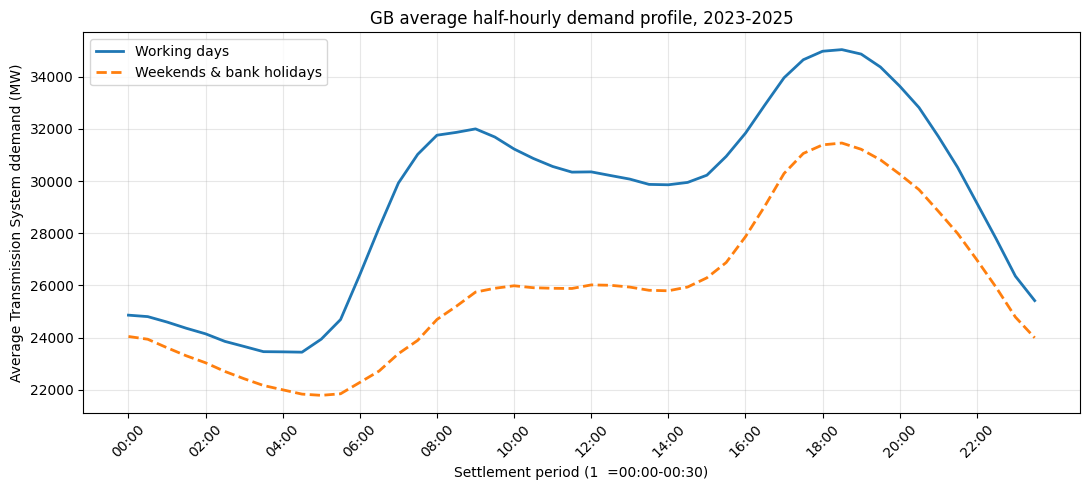

In [14]:
# Plot for visual check

import matplotlib.pyplot as plt   

fig,ax=plt.subplots(figsize=(11,5))
ax.plot(profile["settlement_period"], profile["working_day_mw"],
        label="Working days", linewidth=2)
ax.plot(profile["settlement_period"], profile["non_working_mw"],
        label="Weekends & bank holidays", linewidth=2, linestyle="--")

ax.set_xlabel("Settlement period (1  =00:00-00:30)")
ax.set_ylabel("Average Transmission System ddemand (MW)")
ax.set_title("GB average half-hourly demand profile, 2023-2025")
ax.set_xticks(range(1,49,4))
ax.set_xticklabels([profile.loc[profile["settlement_period"]==p, "time_label"].iloc[0][:5]
                    for p in range(1,49,4)], rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 11. CLosing the connection

In [15]:
conn.commit()
conn.close()
print(f"Connection closed. Database written to {DB_PATH}")
print(f"File size: {DB_PATH.stat().st_size / 1_000_000:.1f} MB")

Connection closed. Database written to c:\Users\marco\Documents\PROJECTS\New folder\database\energy.db
File size: 51.8 MB
